# TASS 2018: rasgos léxicos con Bag-of-Words y TF-IDF

**Curso:** Procesamiento de Lenguaje Natural · Unidad 3 — Clasificación de texto  
**Institución:** Universidad Tecnológica de Bolívar  
**Base:** `bow_softmax_tass.ipynb` (BoW + softmax)  
**Integra:** los antiguos `bow_lexico_tass.ipynb` y `tfidf_lexical_tass.ipynb`  
**Referencia:** Jurafsky & Martin, *Speech and Language Processing* (borrador 2026), cap. 4 y Apéndice B

[TASS](http://tass.sepln.org/) (Taller de Análisis Semántico en la SEPLN) es una campaña de evaluación de análisis de sentimiento en español. La edición 2018 usa tweets etiquetados con cuatro clases de polaridad.

| Etiqueta | Significado |
|---|---|
| **P** | Sentimiento positivo |
| **N** | Sentimiento negativo |
| **NEU** | Neutral: el tweet expresa a la vez polaridad positiva y negativa |
| **NONE** | Sin sentimiento: el tweet es informativo u objetivo |

## Contexto y Propósito

Este notebook clasifica la polaridad de tweets en español (TASS 2018) combinando dos tipos de información: las **palabras** del tweet, representadas con **Bag-of-Words** o **TF-IDF**, y **29 rasgos léxicos diseñados a mano** (pronombres, adverbios, adjetivos, menciones, URL, longitud de palabras) calculados con los módulos de apoyo del curso. Antes de entrenar **audita esos módulos** y encuentra errores que desactivan parte de los rasgos. Después compara cinco representaciones frente a una línea base, prueba dos formas de manejar el desbalance de clases (sobremuestreo dentro de cada partición y pesos por clase) y comprueba con *bootstrap* si las diferencias son reales.

**Objetivo:** responder con evidencia estadística si los rasgos léxicos aportan información que BoW o TF-IDF no capturan, en qué clases ayudan y qué estrategia de desbalance conviene, sin inflar los resultados por fuga de datos.

## Ejemplos de Aplicación en el Mundo Real

Cada caso muestra, paso a paso, cómo se aplica la técnica de este notebook a un problema real.

### Retail, agro y puertos — Reseñas de productos en comercio electrónico

- **Problema:** una tienda en línea quiere detectar productos con mala recepción.
- **Entrada:** reseñas de los compradores.
- **Cómo se aplica TF-IDF + rasgos léxicos:**
  1. Se vectorizan las reseñas con TF-IDF de unigramas y bigramas (`no funciona`, `llegó roto`).
  2. Se calculan los rasgos léxicos y se prueban tres variantes: solo rasgos, solo TF-IDF y la combinación.
  3. Cada variante se compara con la línea base que predice siempre la clase mayoritaria.
- **Salida:** polaridad de cada reseña y porcentaje de negativas por producto.
- **Decisión:** revisar o retirar productos con alto porcentaje de reseñas negativas.

### Salud — Señales de malestar en mensajes

- **Problema:** una línea de orientación necesita decidir qué mensajes revisar primero (uso no diagnóstico).
- **Entrada:** mensajes escritos por los usuarios.
- **Cómo se aplica BoW + rasgos léxicos:**
  1. Se combinan las palabras (BoW) con rasgos como pronombres de primera persona (`yo`, `me`, `mi`), negaciones y adjetivos negativos, señales que la literatura asocia con malestar.
  2. Se entrena el clasificador con pesos por clase.
  3. Se revisan los errores con un profesional para ajustar el umbral.
- **Salida:** puntaje de prioridad por mensaje.
- **Decisión:** orden de atención para el profesional; el modelo nunca responde ni diagnostica.

## Requisitos Previos

**Instalación** (una sola vez, desde la terminal; en Jupyter o Colab antepón `!`):

```bash
pip install numpy pandas scipy scikit-learn imbalanced-learn matplotlib nltk spacy requests
```

**Librerías que se importan:**

| Librería | Para qué se usa |
|---------|-----------------|
| `sys, re, unicodedata, warnings, platform, collections, pathlib` | Utilidades de la biblioteca estándar |
| `numpy, pandas, matplotlib` | Cálculo, tablas y gráficas |
| `sklearn` | `CountVectorizer`, `TfidfVectorizer`, `ColumnTransformer`, escalador, regresión logística, `LinearSVC`, Random Forest, línea base, métricas y particiones |
| `imblearn` | `RandomOverSampler` y `Pipeline` que sobremuestrea dentro de cada partición |
| `logic.text_processing.TextProcessing` | Normalizador y tokenizador de tweets del curso |
| `logic.feature_extraction.FeatureExtraction` | Extractor de los 29 rasgos léxicos del curso |
| `logic.lexical_features.lexical_es` | Léxicos que usan los rasgos (para la auditoría) |

**Datos:** `data/tass/tass2018_es_train.csv` y `tass2018_es_test.csv`. **Código de apoyo:** la carpeta `logic/` debe estar junto a este notebook.

## Marco metodológico: CRISP-ML(Q)

Este notebook sigue **CRISP-ML(Q)** (*Cross-Industry Standard Process for the development of Machine Learning applications with Quality assurance*; Studer et al., 2021). El proceso tiene seis fases, y en cada una se identifican los riesgos de calidad y cómo se mitigan. Las fases aparecen marcadas con 🔷 a lo largo del notebook.

| Fase CRISP-ML(Q) | Dónde se aborda en este notebook | Aseguramiento de calidad |
|------------------|----------------------------------|--------------------------|
| 1. Entendimiento del negocio y de los datos | Pregunta de investigación; sección 2 (carga y distribución de TASS) | Validación de columnas y etiquetas; el notebook se detiene si faltan los datos reales |
| 2. Ingeniería de datos | Secciones 3–4: normalización, variante con acentos, 29 rasgos y auditoría de los módulos | Se verifica sobre tweets reales qué rasgos quedan desactivados por el preprocesamiento original |
| 3. Ingeniería del modelo | Sección 5: cinco representaciones, cuatro clasificadores, dos estrategias de desbalance | Vectorizadores, escalador y sobremuestreo se ajustan **dentro** de cada partición |
| 4. Aseguramiento de calidad del modelo | Secciones 6–7: resultados, fuga W − C, *bootstrap*, F1 por clase, coeficientes, errores | Selección por validación cruzada; *test* se usa una sola vez; intervalos de confianza |
| 5. Despliegue | Al final (fuera de alcance) | — |
| 6. Monitoreo y mantenimiento | Al final (fuera de alcance) | — |

## Estándares de referencia

Prácticas de este notebook alineadas con estándares de IEEE SA, ISO/IEC y la Open Source Initiative (OSI). Se citan como guía de buenas prácticas, no como certificación de cumplimiento.

| Estándar | Cómo se aplica aquí |
|----------|---------------------|
| **ISO/IEC 23894:2023** — Guía para la gestión de riesgos de IA | Se identifica y cuantifica la fuga de datos por sobremuestrear antes de validar (sección 6.2) y se usa el protocolo sin fuga en todo lo demás. |
| **IEEE 7003-2024** — Consideraciones sobre sesgo algorítmico | Se comparan dos tratamientos del desbalance y se reporta el F1 por clase con intervalos, para no ocultar el desempeño en clases minoritarias. |
| **IEEE 2894-2024** — Guía de marco arquitectónico para IA explicable (XAI) | Los coeficientes de los rasgos estandarizados (sección 7.3) explican qué rasgos empujan hacia cada clase. |
| **IEEE 7001-2021** — Transparencia de sistemas autónomos | La auditoría de los módulos (sección 4) documenta qué rasgos no funcionan como su nombre indica. |
| **ISO/IEC 42001:2023** — Sistema de gestión de IA en una organización | Semillas fijas, protocolo explícito y selección del modelo por validación cruzada dejan el experimento auditable. |
| **OSI · Open Source AI Definition 1.0 (2024)** — Qué hace que un sistema de IA sea de código abierto: libertades de usar, estudiar, modificar y compartir, con acceso a código, parámetros e información de los datos | Código del curso y librerías abiertas; el corpus TASS tiene condiciones de uso para investigación. |

## Objetivos de aprendizaje

Al finalizar este notebook podrás:

1. **Explicar** qué capturan los 29 rasgos léxicos (pronombres, adverbios, adjetivos, menciones, URL, longitud), con un ejemplo de tweet para cada grupo.
2. **Auditar** los módulos de apoyo del curso, identificando al menos un error de preprocesamiento que desactive rasgos y su efecto en el F1.
3. **Comparar** cinco representaciones —rasgos solos, BoW, TF-IDF, BoW + rasgos y TF-IDF + rasgos— contra la línea base mayoritaria, con F1 macro y la misma validación cruzada.
4. **Aplicar** dos estrategias contra el desbalance (sobremuestreo dentro de cada partición y pesos por clase) y **justificar** cuál conviene según el F1 por clase.
5. **Evaluar** con *bootstrap* si la diferencia entre el mejor modelo y el segundo es significativa (IC 95 %).
6. **Interpretar** los coeficientes de los rasgos y **explicar** en qué clase aportan más.

## Diseño experimental

**Pregunta de investigación.** ¿Aportan los 29 rasgos léxicos información que BoW o TF-IDF no capturan? ¿Cuánto cambia la respuesta según el preprocesamiento y la forma de tratar el desbalance?

| Bloque | Qué se compara | Clasificador |
|---|---|---|
| **A. Representaciones** | Mayoritaria · Léxico (original) · Léxico (variante) · BoW · TF-IDF · BoW + léxico · TF-IDF + léxico | Regresión logística con pesos por clase |
| **B. No linealidad** | Léxico (variante) | Random Forest |
| **C. Desbalance** | BoW + léxico y TF-IDF + léxico | Regresión logística con pesos · Softmax + sobremuestreo en la partición · SVM lineal con pesos |

**Protocolo.** `StratifiedShuffleSplit` de 10 particiones (75 % / 25 %) sobre *train*; métrica principal F1 macro. Todo lo que aprende de los datos (vectorizador, escalador, sobremuestreo) se ajusta **dentro** de cada partición. *Test* se evalúa una sola vez con los modelos fijados.

## 1. Configuración

La carpeta `logic/` (con `text_processing.py`, `feature_extraction.py`, `lexical_features.py` y `utils.py`) debe estar junto a este notebook.

`feature_extraction.py` importa `utils.Utils`; el `utils.py` incluido es un *stub* mínimo (solo imprime el *traceback*).

In [1]:
# Biblioteca estándar, cálculo y gráficas
import sys, re, unicodedata, warnings, platform
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn: pipelines, vectorizadores, modelos, métricas y validación
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import ShuffleSplit, StratifiedShuffleSplit, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# imbalanced-learn: Pipeline que aplica el sobremuestreo solo al entrenar cada partición
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore", category=FutureWarning)   # los ConvergenceWarning no se silencian
sys.path.insert(0, str(Path.cwd()))

# Módulos de apoyo del curso
from logic.text_processing import TextProcessing
from logic.feature_extraction import FeatureExtraction
from logic.lexical_features import lexical_es

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

import sklearn, imblearn
print("Python", platform.python_version(), "| sklearn", sklearn.__version__, "| imblearn", imblearn.__version__)

Python 3.13.17 | sklearn 1.9.1 | imblearn 0.14.2


> 🔷 **CRISP-ML(Q) · Fase 1 — Entendimiento del negocio y de los datos.** Datos reales de TASS 2018 y distribución de clases.

## 2. Datos: TASS 2018

Se usan **exclusivamente** los CSV reales de TASS 2018. Si no se encuentran, el notebook se detiene con un error que indica las rutas revisadas y los CSV disponibles; no existen datos de respaldo.

In [2]:
# Carpeta de TASS relativa al notebook (y ruta alternativa como texto)
DIR_DATA = Path.cwd() / 'data' / 'tass'
PATH = 'data/tass'
print(f'Directorio de datos: {DIR_DATA}')

Directorio de datos: /home/claude/upd/run/data/tass


In [3]:
# --- Rutas y columnas (ajusta si tus archivos se llaman distinto) ---------------------------------
DIR_CANDIDATES = [Path(DIR_DATA), Path(PATH),]
TRAIN_FILE = "tass2018_es_train.csv"
TEST_FILE  = "tass2018_es_test.csv"
COL_TEXT   = "content"
COL_LABEL  = "sentiment/polarity/value"
LABELS     = ["N", "NEU", "NONE", "P"]

def read_csv_flexible(path):
    return pd.read_csv(path, sep=None, engine="python", encoding="utf-8")


def load_tass():
    for d in DIR_CANDIDATES:
        tr, te = d / TRAIN_FILE, d / TEST_FILE
        if tr.exists():
            df_tr = read_csv_flexible(tr)
            df_te = read_csv_flexible(te) if te.exists() else None
            return df_tr, df_te, f"TASS real ({d})"
    found = [str(p) for d in DIR_CANDIDATES if d.exists() for p in d.glob("*.csv")]
    raise FileNotFoundError(
        f"No se encontró {TRAIN_FILE}. Rutas revisadas: {[str(d) for d in DIR_CANDIDATES]}. "
        f"CSV disponibles: {found}. Ajusta DIR_CANDIDATES, TRAIN_FILE y TEST_FILE.")


df_train, df_test, DATA_SOURCE = load_tass()
print("Fuente de datos:", DATA_SOURCE)
faltan = [c for c in (COL_TEXT, COL_LABEL) if c not in df_train.columns]
if faltan:
    raise KeyError(f"Faltan las columnas {faltan}. Columnas disponibles: {df_train.columns.tolist()}")

# Normalización de etiquetas y validación de test
df_train[COL_LABEL] = df_train[COL_LABEL].astype(str).str.strip().str.upper()
if df_test is not None:
    df_test[COL_LABEL] = df_test[COL_LABEL].astype(str).str.strip().str.upper()
    if not df_test[COL_LABEL].isin(LABELS).any():          # test sin etiquetas públicas
        print("El archivo de test no trae etiquetas válidas: se usa una partición estratificada de train.")
        df_test = None
if df_test is None:
    df_train, df_test = train_test_split(df_train, test_size=0.2, stratify=df_train[COL_LABEL], random_state=SEED)

df_train = df_train.dropna(subset=[COL_TEXT]).reset_index(drop=True)
df_test  = df_test.dropna(subset=[COL_TEXT]).reset_index(drop=True)

dist = pd.DataFrame({"train": df_train[COL_LABEL].value_counts(),
                     "test": df_test[COL_LABEL].value_counts()}).reindex(LABELS)
dist["train_%"] = (100 * dist["train"] / dist["train"].sum()).round(1)
print(f"\ntrain={len(df_train)}  test={len(df_test)}")
dist

Fuente de datos: TASS real (/home/claude/upd/run/data/tass)

train=1008  test=506


,train,test,train_%
sentiment/polarity/value,,,
N,418,219,41.5
NEU,133,69,13.2
NONE,139,62,13.8
P,318,156,31.5


> 🔷 **CRISP-ML(Q) · Fase 2 — Ingeniería de datos.** Preprocesamiento, rasgos léxicos y auditoría de los módulos de apoyo.

## 3. Preprocesamiento y adaptadores

Dos versiones del texto:

- **`clean` (original):** `TextProcessing.transformer(texto)`. Se usa para TF-IDF y como primer preprocesamiento para los rasgos léxicos. Sin eliminación de *stopwords*: en sentimiento, palabras como *no* o *nunca* portan polaridad.
- **`lex_text` (variante):** conserva acentos y sustituye URL, menciones, hashtags y emojis por las etiquetas que `FeatureExtraction` sí cuenta (`url`, `mention`, `hashtag`, `emoji`). Reutiliza `TextProcessing.remove_patterns`.

**Adaptador `LexicalVectorizer`.** `FeatureExtraction.transform()` no sirve directamente en un `Pipeline` de scikit-learn: recibe una lista pero `get_features()` espera *un* mensaje, y además aplica `abs()` (pierde el signo de curtosis y asimetría) y falla con `None` cuando el mensaje queda vacío. El adaptador llama por mensaje a `get_features_lexical()` (que devuelve el vector sin `abs`) y usa un vector de ceros si el mensaje no produce rasgos.

In [4]:
FEATURE_NAMES = [
    "weighted_position", "weighted_normalized",
    "label_mention", "label_url", "label_hashtag", "label_emoji", "label_retweets",
    "lexical_diversity", "label_word",
    "first_person_singular", "second_person_singular", "third_person_singular",
    "first_person_plurar", "second_person_plurar", "third_person_plurar",
    "avg_word", "kur_word", "skew_word",
    "adverb_neg", "adverb_time", "adverb_place", "adverb_mode", "adverb_cant", "adverb_all",
    "adjetives_neg", "adjetives_pos", "who_general", "who_male", "who_female",
]

URL_RE   = re.compile(r"(?i)(?:https?://|www\.)\S+")
EMOJI_RE = re.compile("[\U0001F000-\U000E007F\u2600-\u27BF]")


def normalize_keep_accents(text: str) -> str:
    """Variante de TextProcessing.transformer: conserva acentos/ñ y emite las etiquetas que se cuentan."""
    t = unicodedata.normalize("NFC", str(text)).lower()
    t = URL_RE.sub(" url ", t)
    t = re.sub(r"@\w{1,40}", " mention ", t)
    t = re.sub(r"#\w{1,40}", " hashtag ", t)
    t = EMOJI_RE.sub(" emoji ", t)
    t = TextProcessing.remove_patterns(t)
    return re.sub(r"\s+", " ", t).strip()


def original_clean(text: str) -> str:
    return TextProcessing.transformer(str(text)) or ""


class LexicalVectorizer(BaseEstimator, TransformerMixin):
    """Envuelve FeatureExtraction.get_features_lexical: un vector de 29 rasgos por mensaje."""
    def __init__(self, lang="es"):
        self.lang = lang

    def fit(self, X, y=None):
        self.fe_ = FeatureExtraction(self.lang)
        return self

    def transform(self, X):
        if not hasattr(self, "fe_"):
            self.fit(X)
        rows = []
        for msg in np.asarray(X, dtype=object).ravel():
            try:
                v = self.fe_.get_features_lexical(msg if isinstance(msg, str) else "")
                v = None if v is None else np.asarray(v, dtype=np.float64)
            except Exception:
                v = None
            if v is None or v.shape[0] != len(FEATURE_NAMES) or not np.isfinite(v).all():
                v = np.zeros(len(FEATURE_NAMES))
            rows.append(v)
        return np.vstack(rows)


def build_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Tabla de características. LexicalVectorizer no aprende nada de los datos: calcularlo antes del CV no filtra información."""
    raw = df[COL_TEXT].astype(str)
    out = pd.DataFrame({"raw": raw.values,
                        "clean": raw.map(original_clean).values,
                        "lex_text": raw.map(normalize_keep_accents).values})
    lv = LexicalVectorizer().fit(out["clean"])
    m1, m2 = lv.transform(out["clean"]), lv.transform(out["lex_text"])
    for i, name in enumerate(FEATURE_NAMES):
        out["v1_" + name] = m1[:, i]     # preprocesamiento original
        out["v2_" + name] = m2[:, i]     # variante con acentos y etiquetas
    return out


Xtr, Xte = build_frame(df_train), build_frame(df_test)
# Etiquetas como arreglo NumPy de texto: con pandas ≥ 3 `.values` devuelve un arreglo Arrow que scikit-learn no puede indexar
ytr, yte = df_train[COL_LABEL].to_numpy(dtype=str), df_test[COL_LABEL].to_numpy(dtype=str)
V1 = ["v1_" + n for n in FEATURE_NAMES]
V2 = ["v2_" + n for n in FEATURE_NAMES]
print("Matriz de rasgos por mensaje:", len(FEATURE_NAMES), "columnas léxicas × 2 variantes")
Xtr[["raw", "clean", "lex_text"]].head(6)

Matriz de rasgos por mensaje: 29 columnas léxicas × 2 variantes


,raw,clean,lex_text
0,-Me caes muy bien \r\n-Tienes que jugar más partidas al lol con Russel y conmigo\r\n-P...,me caes muy bien tienes que jugar mas partidas al lol con russel y conmigo por que tan...,me caes muy bien tienes que jugar más partidas al lol con russel y conmigo por qué tan...
1,@myendlesshazza a. que puto mal escribo\r\n\r\nb. me sigo surrando help \r\n\r\n3. ha ...,mention a. que puto mal escribo b. me sigo surrando help 3. ha quedado raro el cometel...,mention a. que puto mal escribo b. me sigo surrando help 3. ha quedado raro el cómetel...
2,@estherct209 jajajaja la tuya y la d mucha gente seguro!! Pero yo no puedo sin mi mele...,mention jajajaja la tuya y la d mucha gente seguro pero yo no puedo sin mi melena me m...,mention jajajaja la tuya y la d mucha gente seguro pero yo no puedo sin mi melena me m...
3,Quiero mogollón a @AlbaBenito99 pero sobretodo por lo rápido que contesta a los wasaps,quiero mogollon a mention pero sobretodo por lo rapido que contesta a los wasaps,quiero mogollón a mention pero sobretodo por lo rápido que contesta a los wasaps
4,Vale he visto la tia bebiendose su regla y me hs dado muchs grima,vale he visto la tia bebiendose su regla y me hs dado muchs grima,vale he visto la tia bebiendose su regla y me hs dado muchs grima
5,@Yulian_Poe @guillermoterry1 Ah. mucho más por supuesto! solo que lo incluyo. Me había...,mention mention ah. mucho mas por supuesto solo que lo incluyo. me habias entendido mal,mention mention ah. mucho más por supuesto solo que lo incluyo. me habías entendido mal


### 3.1 Qué captura cada grupo de rasgos

Para cada grupo se muestra el tweet real de *train* con el valor más alto en ese grupo (variante con acentos y etiquetas).

In [5]:
GRUPOS = {
    "Etiquetas de Twitter": ["label_mention", "label_url", "label_hashtag", "label_emoji", "label_retweets"],
    "Pronombres personales": [n for n in FEATURE_NAMES if "_person_" in n],
    "Adverbios": [n for n in FEATURE_NAMES if n.startswith("adverb_")],
    "Adjetivos de polaridad": ["adjetives_neg", "adjetives_pos"],
    "Referencias a personas": ["who_general", "who_male", "who_female"],
    "Longitud y posición": ["weighted_position", "weighted_normalized", "avg_word", "kur_word", "skew_word", "label_word", "lexical_diversity"],
}
for grupo, rasgos in GRUPOS.items():
    cols = ["v2_" + r for r in rasgos]
    i = int(Xtr[cols].sum(axis=1).idxmax())
    activos = {r: round(float(Xtr.loc[i, "v2_" + r]), 2) for r in rasgos if Xtr.loc[i, "v2_" + r] != 0}
    print(f"[{grupo}] {Xtr.loc[i, 'raw'][:140]}")
    print(f"   rasgos > 0: {activos}\n")

[Etiquetas de Twitter] Buenos días Magaluf !  👌🏻✅
• @BHmallorca • #BHmallorca#Magaluf #Mallorca #Island #Summer2016… https://t.co/amAnsSDaxI
   rasgos > 0: {'label_mention': 1.0, 'label_url': 1.0, 'label_hashtag': 5.0, 'label_emoji': 3.0}

[Pronombres personales] Ese momento en el que no tienes megas para ver el video y en casa de tu padre no hay wifi  #MamaHeAsesinadoAMiNovia
   rasgos > 0: {'second_person_singular': 1.0, 'third_person_singular': 3.0, 'third_person_plurar': 1.0}

[Adverbios] @oh_gabi genial! Ahora ya mucho mejor que con las tres primeras aún así todavía hay cosas que pulir
   rasgos > 0: {'adverb_time': 4.0, 'adverb_mode': 2.0, 'adverb_cant': 1.0, 'adverb_all': 7.0}

[Adjetivos de polaridad] Buen partido a todos @overgame_org , suerte en la final de losers y a ver si nos volvemos a ver en la gran final. Saludo a esos casters
   rasgos > 0: {'adjetives_pos': 4.0}

[Referencias a personas] Porque son tan manipulables los pequeños ? Y porque no ven a su padre igual que a

## 4. Diagnóstico de los módulos de apoyo

Antes de entrenar, se verifica qué hace realmente cada etapa. Estos hallazgos condicionan la interpretación de cualquier resultado posterior.

In [6]:
def elegir_tweet_real(textos):
    """Tweet real de train con más marcas a la vez: emoji, hashtag, acento/ñ, mención y URL."""
    marcas = [EMOJI_RE, re.compile(r"#\w"), re.compile("[áéíóúüñÁÉÍÓÚÜÑ]"), re.compile(r"@\w"), URL_RE]
    puntajes = [sum(bool(m.search(t)) for m in marcas) for t in textos]
    return textos[int(np.argmax(puntajes))]

ejemplo = elegir_tweet_real(df_train[COL_TEXT].astype(str).tolist())      # tweet real, no escrito a mano
t1, t2 = original_clean(ejemplo), normalize_keep_accents(ejemplo)
print("Original         :", ejemplo)
print("transformer()    :", t1)
print("keep_accents()   :", t2)

lv = LexicalVectorizer().fit([ejemplo])
v1 = pd.Series(lv.transform([t1])[0], index=FEATURE_NAMES)
v2 = pd.Series(lv.transform([t2])[0], index=FEATURE_NAMES)
cmp_ = pd.DataFrame({"original": v1, "con acentos/etiquetas": v2})
print("\nRasgos que cambian entre variantes:")
cmp_[cmp_["original"] != cmp_["con acentos/etiquetas"]]

Original         : Buenos días Magaluf !  👌🏻✅
• @BHmallorca • #BHmallorca#Magaluf #Mallorca #Island #Summer2016… https://t.co/amAnsSDaxI
transformer()    : buenos dias magaluf mention hastaghastag hastag hastag hastag url
keep_accents()   : buenos días magaluf emoji emoji emoji • mention • hashtag hashtag hashtag hashtag hashtag … url

Rasgos que cambian entre variantes:


,original,con acentos/etiquetas
weighted_position,2.894444,3.623214
weighted_normalized,4.666667,7.562500
label_hashtag,0.000000,5.000000
label_emoji,0.000000,3.000000
lexical_diversity,0.261500,0.221100
label_word,7.000000,6.000000
avg_word,6.714300,3.333300
kur_word,1.176800,-1.620500
skew_word,1.458700,0.326900


**Lo que muestra la celda anterior** (sobre un tweet real de *train*, elegido por reunir emoji, hashtag, acentos, mención y URL; si el elegido no tiene alguna de esas marcas, el efecto correspondiente no se observa en él y se verifica en la tabla de cobertura siguiente):

1. `transformer()` aplica `proper_encoding` (NFD → ASCII con `ignore`) **antes** de buscar emojis. El emoji desaparece y la etiqueta `[EMOJI]` nunca se genera, por lo que `label_emoji` vale siempre 0.
2. La etiqueta de hashtag se emite como `hastag` (errata), pero `FeatureExtraction` cuenta `hashtag`. `label_hashtag` vale siempre 0.
3. Se eliminan los acentos y la ñ (*más* → *mas*, *niño* → *nino*), pero los léxicos contienen entradas con acento. Esas entradas no pueden coincidir.

In [7]:
# Alcanzabilidad del léxico: entradas que ningún token puede igualar con cada preprocesamiento
cats = [k for k in lexical_es if k != "hate"]        # 'hate' no la usa FeatureExtraction
rows = []
for k in cats:
    entries = lexical_es[k]
    con_acento = [w for w in entries if w != TextProcessing.proper_encoding(w)]
    multipalabra = [w for w in entries if " " in w.strip()]
    rows.append({"categoría": k, "entradas": len(entries),
                 "inalcanzables_original": len(set(con_acento) | set(multipalabra)),
                 "inalcanzables_variante": len(set(multipalabra))})
reach = pd.DataFrame(rows).set_index("categoría")
reach.loc["TOTAL"] = reach.sum()
reach["% perdido (original)"] = (100 * reach["inalcanzables_original"] / reach["entradas"]).round(1)
display(reach)

solape = sorted(set(lexical_es["adjetives_neg"]) & set(lexical_es["adjetives_pos"]))
print(f"\nAdjetivos presentes a la vez en 'adjetives_neg' y 'adjetives_pos' ({len(solape)}):", solape)
ambiguos = [w for k in ["first_person_singular", "third_person_singular"] for w in lexical_es[k] if w in ("el", "mi", "tu", "ese")]
print("Entradas ambiguas (artículo/posesivo/demostrativo tratadas como pronombre personal):",
      sorted(set(ambiguos + [w for w in lexical_es["second_person_singular"] if w == "tu"])))

,entradas,inalcanzables_original,inalcanzables_variante,% perdido (original)
categoría,,,,
first_person_singular,3,0,0,0.0
second_person_singular,5,1,0,20.0
third_person_singular,6,1,0,16.7
first_person_plurar,2,0,0,0.0
second_person_plurar,5,0,0,0.0
third_person_plurar,6,0,0,0.0
adverb_time,12,4,0,33.3
adverb_neg,4,1,1,25.0
adverb_place,13,5,0,38.5



Adjetivos presentes a la vez en 'adjetives_neg' y 'adjetives_pos' (6): ['caliente', 'diferente', 'duro', 'imposible', 'popular', 'salado']
Entradas ambiguas (artículo/posesivo/demostrativo tratadas como pronombre personal): ['el', 'ese', 'mi', 'tu']


In [8]:
# Efecto sobre el corpus: cobertura de rasgos y redundancia de rasgos de posición
n_tokens = Xtr["clean"].map(lambda s: len(TextProcessing.tokenizer(s) or []))
resumen = pd.DataFrame({
    "% mensajes con valor > 0 (original)": (Xtr[V1] > 0).mean().values * 100,
    "% mensajes con valor > 0 (variante)": (Xtr[V2] > 0).mean().values * 100,
}, index=FEATURE_NAMES).round(1)
display(resumen.loc[["label_hashtag", "label_emoji", "first_person_singular", "second_person_singular",
                     "adverb_time", "adverb_place", "adverb_mode", "adjetives_neg", "adjetives_pos"]])

r_wp = np.corrcoef(Xtr["v1_weighted_position"], np.log1p(n_tokens))[0, 1]
r_wn = np.corrcoef(Xtr["v1_weighted_normalized"], n_tokens)[0, 1]
print(f"\ncorr(weighted_position, log(1+n_tokens))  = {r_wp:.3f}")
print(f"corr(weighted_normalized, n_tokens)       = {r_wn:.3f}")
zeros = int((Xtr[V1].abs().sum(axis=1) == 0).sum())
print(f"Mensajes con vector léxico vacío (original): {zeros} de {len(Xtr)}")

,% mensajes con valor > 0 (original),% mensajes con valor > 0 (variante)
label_hashtag,0.0,7.1
label_emoji,0.0,3.3
first_person_singular,17.9,17.3
second_person_singular,4.9,4.9
adverb_time,18.0,18.7
adverb_place,1.4,3.4
adverb_mode,10.0,12.5
adjetives_neg,13.0,13.3
adjetives_pos,21.7,22.2



corr(weighted_position, log(1+n_tokens))  = 0.733
corr(weighted_normalized, n_tokens)       = 0.984
Mensajes con vector léxico vacío (original): 0 de 1008


**Hallazgos adicionales (verificables en las celdas anteriores):**

- `weighted_position` es la suma de 1/(1+índice de la *primera* aparición de cada token); con tokens sin repetir equivale al número armónico H(n). `weighted_normalized` equivale a (n+1)/2. Ambos son, en la práctica, funciones de la longitud del mensaje y no de la posición de las palabras. Una correlación alta con la longitud (celda anterior) lo confirma.
- `lexical_diversity` calcula la proporción de **caracteres** distintos sobre el total de caracteres, no una razón tipo/token de palabras. Mide algo distinto a lo que sugiere su nombre.
- Las entradas multipalabra (`en absoluto`, `bestia negra`) no coinciden nunca porque la comparación es por token.
- Los léxicos contienen palabras no relacionadas con polaridad en `adjetives_neg`/`adjetives_pos` (colores, tamaños) y entradas en ambas listas. Es un léxico de categorías gramaticales/semánticas, no un léxico de sentimiento validado.
- `el` (artículo) está en `third_person_singular`, por lo que cada aparición del artículo suma como pronombre personal (lo mismo ocurre con `mi`, `tu` y `ese`).

**Consecuencia para el experimento:** el enfoque léxico puede compararse en dos condiciones (original y variante). La diferencia entre ambas cuantifica cuánto pesa el preprocesamiento sobre el rendimiento.

> 🔷 **CRISP-ML(Q) · Fase 3 — Ingeniería del modelo.** Cinco representaciones, cuatro clasificadores y dos estrategias de desbalance, con validación cruzada sin fuga.

## 5. Experimentos

### 5.1 Componentes

- **BoW:** `CountVectorizer` de 1 a 3 palabras sobre `clean` (como en `bow_softmax_tass`).
- **TF-IDF:** unigramas y bigramas con el tokenizador de tweets del curso, términos en ≥ 2 tweets y `sublinear_tf`.
- **Rasgos léxicos:** las 29 columnas, estandarizadas con `StandardScaler` (sus escalas son muy distintas a las de BoW/TF-IDF).
- **Clasificadores:**

| Clasificador | Manejo del desbalance |
|---|---|
| **LR + pesos** | `LogisticRegression(class_weight="balanced")`: un error en una clase minoritaria cuesta más |
| **Softmax + ROS** | `RandomOverSampler` duplica tweets de las clases minoritarias **solo** en el entrenamiento de cada partición; `LogisticRegression(C=10)` como en `bow_softmax_tass` |
| **SVM + pesos** | `LinearSVC(class_weight="balanced")`; lineal porque con miles de n-gramas rinde como un núcleo no lineal y entrena mucho más rápido |
| **Random Forest** | `class_weight="balanced_subsample"`; solo sobre rasgos léxicos, para ver si hay interacciones no lineales entre ellos |

In [9]:
# Representaciones de texto
def bow():
    return CountVectorizer(analyzer="word", ngram_range=(1, 3))

def tfidf():
    return TfidfVectorizer(tokenizer=TextProcessing.tokenizer, token_pattern=None, lowercase=False,
                           ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Clasificadores
def lr_pesos():
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, random_state=SEED)

def softmax():
    return LogisticRegression(C=10, max_iter=1000)            # el de bow_softmax_tass

def svm_pesos():
    return LinearSVC(C=1.0, class_weight="balanced", max_iter=10000, random_state=SEED)

def rf():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)


def features(text_vec=None, lex_cols=None):
    """ColumnTransformer con texto (BoW o TF-IDF sobre 'clean') y/o rasgos léxicos escalados."""
    parts = []
    if text_vec is not None:
        parts.append(("texto", text_vec(), "clean"))
    if lex_cols:
        parts.append(("lex", StandardScaler(), lex_cols))
    return ColumnTransformer(parts, sparse_threshold=0.3)


def pipe(text_vec, lex_cols, clf):
    """Pipeline completo. Con 'Softmax + ROS' el sobremuestreo va entre las características y el modelo."""
    if clf == "Softmax + ROS":
        return ImbPipeline([("feat", features(text_vec, lex_cols)), ("ros", RandomOverSampler(random_state=SEED)), ("clf", softmax())])
    modelo = {"LR + pesos": lr_pesos, "SVM + pesos": svm_pesos, "Random Forest": rf}[clf]()
    return Pipeline([("feat", features(text_vec, lex_cols)), ("clf", modelo)])


EXPERIMENTS = {
    # A. Representaciones (mismo clasificador)
    "A0 · Mayoritaria":                Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    "A1 · Léxico (original) · LR":     pipe(None, V1, "LR + pesos"),
    "A2 · Léxico (variante) · LR":     pipe(None, V2, "LR + pesos"),
    "A3 · BoW · LR":                   pipe(bow, None, "LR + pesos"),
    "A4 · TF-IDF · LR":                pipe(tfidf, None, "LR + pesos"),
    "A5 · BoW + léxico · LR":          pipe(bow, V2, "LR + pesos"),
    "A6 · TF-IDF + léxico · LR":       pipe(tfidf, V2, "LR + pesos"),
    # B. No linealidad sobre los rasgos
    "B1 · Léxico (variante) · RF":     pipe(None, V2, "Random Forest"),
    # C. Desbalance (las filas A5 y A6 son la variante 'LR + pesos')
    "C1 · BoW + léxico · Softmax+ROS": pipe(bow, V2, "Softmax + ROS"),
    "C2 · BoW + léxico · SVM":         pipe(bow, V2, "SVM + pesos"),
    "C3 · TF-IDF + léxico · Softmax+ROS": pipe(tfidf, V2, "Softmax + ROS"),
    "C4 · TF-IDF + léxico · SVM":      pipe(tfidf, V2, "SVM + pesos"),
}
print(len(EXPERIMENTS), "experimentos")

12 experimentos


### 5.2 Validación cruzada sobre *train*

In [10]:
# 10 particiones estratificadas 75 % / 25 %; el Pipeline garantiza que nada aprende de la partición de validación
cv = StratifiedShuffleSplit(n_splits=10, test_size=0.25, random_state=SEED)
cv_rows = []
for name, p in EXPERIMENTS.items():
    res = cross_validate(p, Xtr, ytr, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=1)
    cv_rows.append({"experimento": name, "CV macro-F1": res["test_f1"].mean(),
                    "± std": res["test_f1"].std(), "CV accuracy": res["test_acc"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("experimento").round(4)
print("Fuente de datos:", DATA_SOURCE)
cv_table

Fuente de datos: TASS real (/home/claude/upd/run/data/tass)


,CV macro-F1,± std,CV accuracy
experimento,,,
A0 · Mayoritaria,0.1465,0.0005,0.4143
A1 · Léxico (original) · LR,0.3233,0.0263,0.3603
A2 · Léxico (variante) · LR,0.3468,0.0226,0.3810
A3 · BoW · LR,0.3748,0.0288,0.5063
A4 · TF-IDF · LR,0.4151,0.0311,0.4687
A5 · BoW + léxico · LR,0.3724,0.0227,0.4940
A6 · TF-IDF + léxico · LR,0.3888,0.0394,0.4409
B1 · Léxico (variante) · RF,0.3329,0.0215,0.4782
C1 · BoW + léxico · Softmax+ROS,0.3725,0.0249,0.4980


### 5.3 Evaluación final en *test* (una sola vez)

In [11]:
fitted, preds, test_rows = {}, {}, []
for name, p in EXPERIMENTS.items():
    p.fit(Xtr, ytr)
    fitted[name], preds[name] = p, p.predict(Xte)
    test_rows.append({"experimento": name,
                      "test macro-F1": f1_score(yte, preds[name], average="macro", labels=LABELS),
                      "test accuracy": accuracy_score(yte, preds[name])})
final = cv_table[["CV macro-F1", "± std"]].join(pd.DataFrame(test_rows).set_index("experimento").round(4))
final

,CV macro-F1,± std,test macro-F1,test accuracy
experimento,,,,
A0 · Mayoritaria,0.1465,0.0005,0.1510,0.4328
A1 · Léxico (original) · LR,0.3233,0.0263,0.3129,0.3458
A2 · Léxico (variante) · LR,0.3468,0.0226,0.3396,0.3715
A3 · BoW · LR,0.3748,0.0288,0.3916,0.5257
A4 · TF-IDF · LR,0.4151,0.0311,0.4133,0.4822
A5 · BoW + léxico · LR,0.3724,0.0227,0.3773,0.4862
A6 · TF-IDF + léxico · LR,0.3888,0.0394,0.3767,0.4328
B1 · Léxico (variante) · RF,0.3329,0.0215,0.3058,0.4565
C1 · BoW + léxico · Softmax+ROS,0.3725,0.0249,0.3654,0.4881


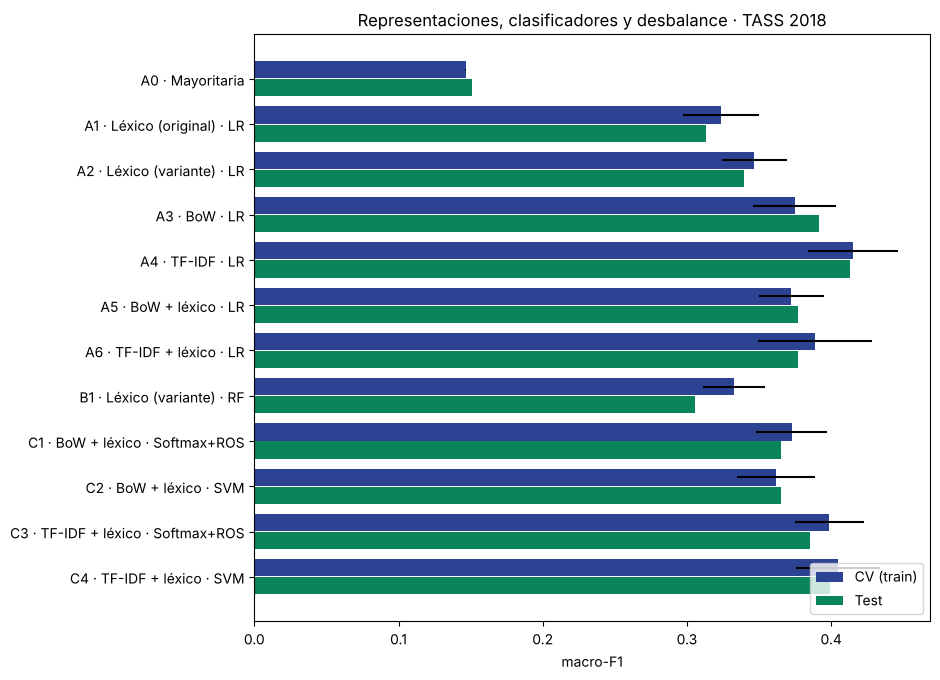

In [12]:
# Barras: F1 macro en CV (con desviación) y en test
fig, ax = plt.subplots(figsize=(9.5, 0.45 * len(final) + 1.5))
y = np.arange(len(final))
ax.barh(y - 0.2, final["CV macro-F1"], height=0.38, xerr=final["± std"], label="CV (train)", color="#2C4293")
ax.barh(y + 0.2, final["test macro-F1"], height=0.38, label="Test", color="#098559")
ax.set_yticks(y); ax.set_yticklabels(final.index); ax.invert_yaxis()
ax.set_xlabel("macro-F1"); ax.legend(loc="lower right")
ax.set_title("Representaciones, clasificadores y desbalance · TASS 2018")
plt.tight_layout(); plt.show()

> **Cómo leer la tabla.**
>
> - **A0 → A1/A2:** ¿superan los rasgos solos a la línea base? La diferencia A1 → A2 mide el costo de los errores de preprocesamiento encontrados en la sección 4.
> - **A3 vs. A4:** BoW frente a TF-IDF con el mismo clasificador.
> - **A3 → A5 y A4 → A6:** cuánto añaden los rasgos léxicos a cada representación de palabras.
> - **A2 vs. B1:** si Random Forest mejora claramente sobre los mismos rasgos, hay interacciones no lineales entre ellos.
> - **A5 / C1 / C2 y A6 / C3 / C4:** pesos por clase frente a sobremuestreo, con la misma representación.

> 🔷 **CRISP-ML(Q) · Fase 4 — Aseguramiento de calidad del modelo.** Significancia de las diferencias, fuga por sobremuestrear antes de validar, F1 por clase, coeficientes y errores.

## 6. ¿Las diferencias son reales?

### 6.1 *Bootstrap* pareado sobre *test*

Se remuestrean los **mismos** tweets para los dos modelos y se calcula la diferencia de F1 macro. Si el intervalo del 95 % incluye 0, la diferencia no es demostrable con este tamaño de *test*. Se comparan el mejor y el segundo modelo según CV, y los pares clave del diseño.

In [13]:
def paired_bootstrap(y_true, p_a, p_b, n=1000, seed=SEED):
    """Diferencia de macro-F1 (b − a) con IC 95 % por bootstrap pareado."""
    rng = np.random.default_rng(seed)
    y_true, p_a, p_b = map(np.asarray, (y_true, p_a, p_b))
    idx, diffs = np.arange(len(y_true)), []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        diffs.append(f1_score(y_true[s], p_b[s], average="macro") - f1_score(y_true[s], p_a[s], average="macro"))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(np.mean(diffs)), float(lo), float(hi)

# Mejor y segundo según CV (nunca según test)
ranking = cv_table["CV macro-F1"].drop("A0 · Mayoritaria").sort_values(ascending=False)
best_name, second_name = ranking.index[0], ranking.index[1]
comparaciones = [
    (second_name, best_name),
    ("A0 · Mayoritaria", "A2 · Léxico (variante) · LR"),
    ("A1 · Léxico (original) · LR", "A2 · Léxico (variante) · LR"),
    ("A3 · BoW · LR", "A5 · BoW + léxico · LR"),
    ("A4 · TF-IDF · LR", "A6 · TF-IDF + léxico · LR"),
    ("A5 · BoW + léxico · LR", "C1 · BoW + léxico · Softmax+ROS"),
    ("A6 · TF-IDF + léxico · LR", "C3 · TF-IDF + léxico · Softmax+ROS"),
]
filas = []
for a, b in comparaciones:
    d, lo, hi = paired_bootstrap(yte, preds[a], preds[b])
    filas.append({"A": a, "B": b, "Δ macro-F1 (B−A)": round(d, 4), "IC95% inf": round(lo, 4),
                  "IC95% sup": round(hi, 4), "IC excluye 0": (lo > 0) or (hi < 0)})
print("Mejor según CV:", best_name, "| segundo:", second_name)
pd.DataFrame(filas)

Mejor según CV: A4 · TF-IDF · LR | segundo: C4 · TF-IDF + léxico · SVM


,A,B,Δ macro-F1 (B−A),IC95% inf,IC95% sup,IC excluye 0
0,C4 · TF-IDF + léxico · SVM,A4 · TF-IDF · LR,0.0144,-0.0207,0.0523,False
1,A0 · Mayoritaria,A2 · Léxico (variante) · LR,0.1889,0.1440,0.2340,True
2,A1 · Léxico (original) · LR,A2 · Léxico (variante) · LR,0.0266,-0.0010,0.0554,False
3,A3 · BoW · LR,A5 · BoW + léxico · LR,-0.0140,-0.0487,0.0219,False
4,A4 · TF-IDF · LR,A6 · TF-IDF + léxico · LR,-0.0358,-0.0788,0.0069,False
5,A5 · BoW + léxico · LR,C1 · BoW + léxico · Softmax+ROS,-0.0119,-0.0320,0.0043,False
6,A6 · TF-IDF + léxico · LR,C3 · TF-IDF + léxico · Softmax+ROS,0.0079,-0.0323,0.0438,False


### 6.2 Fuga de datos: sobremuestrear antes de validar (protocolo W)

El *workshop* original aplicaba `RandomOverSampler` a **todo** *train* y luego hacía la validación cruzada. Como el sobremuestreo duplica tweets, copias del mismo tweet quedan a la vez en entrenamiento y validación: el modelo se evalúa con tweets que ya vio.

- **Protocolo W:** sobremuestrear todo *train* → `ShuffleSplit`.
- **Protocolo C** (el usado en todo el notebook): el sobremuestreo ocurre dentro de cada partición de entrenamiento.

La diferencia W − C cuantifica cuánto se infla la métrica. Se mide con el mejor modelo de tipo *Softmax + ROS*.

In [14]:
def cv_protocolo_w(p_sin_ros, X, y, n_splits=10):
    """Protocolo W: sobremuestrea TODO train y luego valida (con fuga por duplicados)."""
    ros = RandomOverSampler(random_state=SEED)
    ros.fit_resample(np.zeros((len(y), 1)), y)
    idx = ros.sample_indices_
    Xb, yb = X.iloc[idx].reset_index(drop=True), y[idx]
    res = cross_validate(p_sin_ros, Xb, yb, cv=ShuffleSplit(n_splits=n_splits, test_size=0.25, random_state=SEED),
                         scoring="f1_macro", n_jobs=1)
    return res["test_score"]

ros_exps = [n for n in EXPERIMENTS if "Softmax+ROS" in n]
mejor_ros = cv_table.loc[ros_exps, "CV macro-F1"].idxmax()
text_vec = bow if "BoW" in mejor_ros else tfidf
f1_w = cv_protocolo_w(Pipeline([("feat", features(text_vec, V2)), ("clf", softmax())]), Xtr, ytr)
fuga = pd.DataFrame({"CV macro-F1": [f1_w.mean(), cv_table.loc[mejor_ros, "CV macro-F1"]],
                     "Test macro-F1": [final.loc[mejor_ros, "test macro-F1"]] * 2},
                    index=["Protocolo W (con fuga)", "Protocolo C (sin fuga)"]).round(4)
print("Modelo:", mejor_ros)
print(f"Fuga W − C = {fuga.iloc[0, 0] - fuga.iloc[1, 0]:+.4f}")
fuga

Modelo: C3 · TF-IDF + léxico · Softmax+ROS
Fuga W − C = +0.3998


,CV macro-F1,Test macro-F1
Protocolo W (con fuga),0.7985,0.3855
Protocolo C (sin fuga),0.3987,0.3855


> **Interpretación de la salida:** el protocolo con fuga da un F1 de validación más alto que el que el modelo obtiene en *test*; el protocolo C se acerca más a *test* porque evalúa con tweets que el modelo no vio. Cuanto mayor la diferencia W − C, más memoriza el modelo los duplicados (trigramas y `C=10` lo favorecen).

## 7. Análisis del mejor modelo

### 7.1 F1 por clase: ¿dónde ayudan los rasgos y el tratamiento del desbalance?

In [15]:
# F1 de cada clase en test para los experimentos de interés
claves = ["A3 · BoW · LR", "A5 · BoW + léxico · LR", "A4 · TF-IDF · LR", "A6 · TF-IDF + léxico · LR",
          "C1 · BoW + léxico · Softmax+ROS", "C2 · BoW + léxico · SVM", "C3 · TF-IDF + léxico · Softmax+ROS", "C4 · TF-IDF + léxico · SVM"]
per_class = pd.DataFrame({n: f1_score(yte, preds[n], average=None, labels=LABELS, zero_division=0) for n in claves},
                         index=LABELS).round(3)
per_class["Δ léxico (BoW)"] = (per_class["A5 · BoW + léxico · LR"] - per_class["A3 · BoW · LR"]).round(3)
per_class["Δ léxico (TF-IDF)"] = (per_class["A6 · TF-IDF + léxico · LR"] - per_class["A4 · TF-IDF · LR"]).round(3)
per_class.T

,N,NEU,NONE,P
A3 · BoW · LR,0.657,0.168,0.206,0.535
A5 · BoW + léxico · LR,0.606,0.173,0.215,0.516
A4 · TF-IDF · LR,0.625,0.235,0.267,0.527
A6 · TF-IDF + léxico · LR,0.537,0.224,0.221,0.525
C1 · BoW + léxico · Softmax+ROS,0.612,0.137,0.193,0.519
C2 · BoW + léxico · SVM,0.635,0.155,0.154,0.516
C3 · TF-IDF + léxico · Softmax+ROS,0.613,0.237,0.148,0.544
C4 · TF-IDF + léxico · SVM,0.620,0.211,0.205,0.560
Δ léxico (BoW),-0.051,0.005,0.009,-0.019
Δ léxico (TF-IDF),-0.088,-0.011,-0.046,-0.002


### 7.2 Reporte, incertidumbre por clase y matriz de confusión del mejor modelo (según CV)

Mejor por CV: A4 · TF-IDF · LR 

              precision    recall  f1-score   support

           N      0.655     0.598     0.625       219
         NEU      0.204     0.275     0.235        69
        NONE      0.227     0.323     0.267        62
           P      0.592     0.474     0.527       156

    accuracy                          0.482       506
   macro avg      0.420     0.418     0.413       506
weighted avg      0.522     0.482     0.498       506



,soporte,F1,IC95% inf,IC95% sup
N,219,0.625,0.569,0.675
NEU,69,0.235,0.142,0.316
NONE,62,0.267,0.176,0.354
P,156,0.527,0.454,0.597


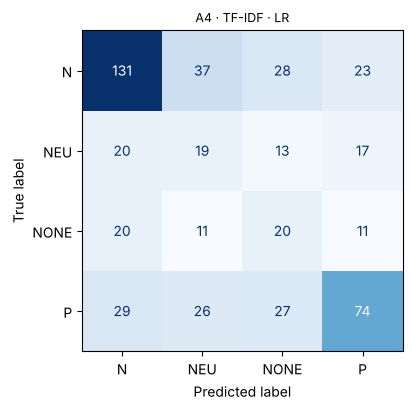

In [16]:
print("Mejor por CV:", best_name, "\n")
print(classification_report(yte, preds[best_name], labels=LABELS, zero_division=0, digits=3))

# Intervalo de confianza del F1 de cada clase (bootstrap sobre test)
def f1_ci_por_clase(y_true, y_pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    idx, f = np.arange(len(y_true)), []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        f.append(f1_score(y_true[s], y_pred[s], average=None, labels=LABELS, zero_division=0))
    return np.percentile(f, 2.5, axis=0), np.percentile(f, 97.5, axis=0)

lo, hi = f1_ci_por_clase(yte, preds[best_name])
sup = pd.Series(yte).value_counts().reindex(LABELS).fillna(0).astype(int)
display(pd.DataFrame({"soporte": sup.values,
                      "F1": f1_score(yte, preds[best_name], average=None, labels=LABELS, zero_division=0).round(3),
                      "IC95% inf": lo.round(3), "IC95% sup": hi.round(3)}, index=LABELS))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(yte, preds[best_name], labels=LABELS, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(best_name, fontsize=9); plt.tight_layout(); plt.show()

> **Interpretación de la salida:** el soporte es el número de tweets reales de cada clase en *test*. Con pocos ejemplos, el F1 de esa clase es inestable: por eso el intervalo importa más que el valor puntual, y una diferencia entre modelos en una clase de soporte bajo (`NEU`) rara vez es demostrable.

### 7.3 Qué aprendieron los modelos de los rasgos léxicos

Coeficientes de los rasgos estandarizados en los modelos híbridos con regresión logística. Son comparables entre sí dentro de un modelo. Un coeficiente alto en una clase empuja la predicción hacia ella **manteniendo constante el resto**, incluidas las palabras.

In [17]:
for name in ["A5 · BoW + léxico · LR", "A6 · TF-IDF + léxico · LR"]:
    clf = fitted[name].named_steps["clf"]
    coef = pd.DataFrame(clf.coef_[:, -len(FEATURE_NAMES):], index=clf.classes_, columns=FEATURE_NAMES).T
    coef["|max|"] = coef.abs().max(axis=1)
    print(name)
    display(coef.sort_values("|max|", ascending=False).head(10).drop(columns="|max|").round(3))

A5 · BoW + léxico · LR


,N,NEU,NONE,P
adjetives_neg,0.526,-0.032,-0.302,-0.193
adjetives_pos,-0.319,-0.135,0.045,0.409
adverb_cant,-0.028,0.196,-0.355,0.187
who_general,-0.039,-0.097,-0.196,0.331
kur_word,-0.008,0.102,0.209,-0.303
adverb_all,0.136,0.063,-0.303,0.103
adverb_neg,0.301,0.011,-0.039,-0.273
label_mention,-0.286,0.096,0.213,-0.023
adverb_mode,0.080,-0.053,-0.278,0.250
skew_word,0.093,-0.037,-0.257,0.200


A6 · TF-IDF + léxico · LR


,N,NEU,NONE,P
adjetives_neg,0.337,0.028,-0.280,-0.084
who_general,0.097,-0.180,-0.237,0.320
kur_word,0.052,0.137,0.114,-0.302
adverb_neg,0.270,0.067,-0.130,-0.207
adjetives_pos,-0.221,-0.100,0.059,0.261
second_person_plurar,0.096,-0.254,0.158,0.001
label_hashtag,0.012,-0.254,0.061,0.181
label_mention,-0.251,-0.020,0.251,0.021
weighted_normalized,0.231,-0.112,-0.250,0.131
adverb_all,0.095,0.069,-0.237,0.073


### 7.4 Ejemplos mal clasificados por el mejor modelo

In [18]:
err = pd.DataFrame({"texto": Xte["raw"], "real": yte, "predicho": preds[best_name]})
err = err[err["real"] != err["predicho"]]
print(f"Errores: {len(err)} de {len(Xte)} ({100 * len(err) / len(Xte):.1f} %)")
err.sample(min(10, len(err)), random_state=SEED).reset_index(drop=True)

Errores: 262 de 506 (51.8 %)


,texto,real,predicho
0,Tengo los md abiertos Crushes,NONE,P
1,@ClaudioSensasao @MsRose_84 @geraldine_balme ¡Cada vez sois más! Las risas están asegu...,P,NEU
2,Plan perfecto para terminar el fin de semana. @AthleticClub - @FCBarcelona_es. Después...,P,NONE
3,"@carlosgterol @MataTweet Si, ayer estuvimos reunidos en Moncloa, pero al final habrá q...",NONE,NEU
4,Aquí tenéis el segundo vídeo del día 14 días para tener PES 2017 y la demo de FIFA 17...,P,NONE
5,@UniversoMujer18 ya se acabo la hora jajaja estoy expectante a ver si me ha tocado el ...,P,N
6,"@BenitoVGC el Sabueso es muy malo, el leñador mola \r\n\r\nQuiero minero y mago de hielo",NEU,P
7,@Davorias Pero es que está muy rica,P,NEU
8,"@SoofRawr + ni el de al lado, la ""manita"" que usas para que se vea como más negro",NONE,N
9,@ArthasSama @Holic_meri es por no destrozar tus posibilidades con la gente guapa,NEU,P


## 8. Interpretación y límites

**Preguntas que deben responder los números:**

1. ¿Supera algún enfoque solo con rasgos a la línea base? Si no lo hace de forma clara, los 29 rasgos no bastan por sí solos para la polaridad.
2. ¿Cuánto cuestan los errores de preprocesamiento (A1 vs. A2)?
3. ¿Aportan los rasgos sobre BoW o TF-IDF (A3 → A5, A4 → A6)? Si el intervalo *bootstrap* incluye 0, la respuesta es "no demostrable con este *test*".
4. ¿Qué estrategia de desbalance da mejor F1 en `NEU` y `NONE`, las clases con menos señal léxica de polaridad?
5. ¿Cuánto inflaba la métrica el protocolo con fuga?

**Limitaciones.**

- Los léxicos del curso son de categorías gramaticales y semánticas, no un léxico de sentimiento validado (sección 4).
- `weighted_position` y `weighted_normalized` son casi funciones de la longitud; `lexical_diversity` mide diversidad de caracteres.
- Hiperparámetros sin ajustar (`C=1` en LR y SVM, `C=10` en Softmax): una diferencia entre clasificadores puede deberse a `C` y no al método de balanceo. Para separarlos hay que buscar `C` dentro de la validación cruzada (`GridSearchCV` sobre el `Pipeline`).
- Una sola partición *train/test* y una semilla: el *bootstrap* cubre la variabilidad de *test*, no la del reentrenamiento.
- **Referencia externa:** en el *Overview of TASS 2018* (InterTASS ES, Tabla 4) el mejor sistema obtuvo macro-F1 = 0.503 (Martínez-Cámara et al., 2018, CEUR-WS vol. 2172). Esa comparación solo vale si tu *test* es el oficial de 1 899 tweets.

**Extensiones.** Ablación por grupos de rasgos; corregir los errores de los módulos y repetir; sustituir los léxicos por uno de polaridad validado; comparar con *embeddings* o con BETO (`bert_classifier.ipynb`).

**Defensa oral.** Explica por qué `CountVectorizer`, `TfidfVectorizer`, `StandardScaler` y `RandomOverSampler` deben ajustarse dentro de cada partición, mientras que `LexicalVectorizer` puede calcularse antes de la validación cruzada.

---

> 🔷 **CRISP-ML(Q) · Fases 5 y 6 — Despliegue, monitoreo y mantenimiento.** Están fuera del alcance de este notebook académico, pero así se abordarían:
>
> - **Despliegue:** guardar el `Pipeline` elegido con `joblib` e incluir en el servicio la misma función `build_frame` (normalización + rasgos léxicos), porque el modelo depende de ella.
> - **Monitoreo y mantenimiento:** vigilar la proporción de tweets con vector léxico vacío, de términos desconocidos para el vectorizador y la distribución de clases predichas; si cambian, el lenguaje cambió y hay que reetiquetar una muestra y reentrenar.